## TELECOM CUSTEMER CHURN PREDICTION

In [112]:
import pandas as pd

In [113]:
df=pd.read_csv("C:\\Users\\AmbiA\\OneDrive\\Documents\\Telecom_Customer_Churn_Dataset.csv")

## DATA CLEANING
### DROPING NULL VALUES

In [114]:
df=df.dropna()

## DROPING DUPLICATE VALUES

In [115]:
df=df.drop_duplicates()

In [116]:
df

,CustomerID,Tenure_Months,Monthly_Charges,Total_Charges,Contract_Type,Internet_Service,Payment_Method,Churn
0,CUST00001,52,1541.42,75408.44,Two Year,No,UPI,No
1,CUST00002,15,1317.97,73419.49,Month-to-Month,DSL,Bank Transfer,No
2,CUST00003,61,409.64,87681.15,Month-to-Month,No,Credit Card,No
3,CUST00004,21,1791.31,72417.07,Two Year,DSL,Bank Transfer,No
4,CUST00005,24,1791.34,23568.21,One Year,Fiber Optic,Debit Card,No
...,...,...,...,...,...,...,...,...
2495,CUST02496,33,479.19,25890.63,Month-to-Month,No,Debit Card,No
2496,CUST02497,52,1241.50,85917.79,Two Year,No,Credit Card,No
2497,CUST02498,14,1172.06,54865.85,Month-to-Month,No,Credit Card,Yes
2498,CUST02499,53,778.37,57162.91,One Year,Fiber Optic,UPI,No


## LABEL ENCODING

In [117]:
a=df.select_dtypes(include=["object"])
a=a.drop("CustomerID",axis=1)

C:\Users\AmbiA\AppData\Local\Temp\ipykernel_19748\1665018773.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  a=df.select_dtypes(include=["object"])


In [118]:
from sklearn.preprocessing import LabelEncoder

In [119]:
for i in a:
     a[i]=LabelEncoder().fit_transform(a[i])
    

In [120]:
a

,Contract_Type,Internet_Service,Payment_Method,Churn
0,2,2,3,0
1,0,0,0,0
2,0,2,1,0
3,2,0,0,0
4,1,1,2,0
...,...,...,...,...
2495,0,2,2,0
2496,2,2,1,0
2497,0,2,1,1
2498,1,1,3,0


## FEATURE SCALING

In [121]:
import numpy as np

In [122]:
b=df.select_dtypes(include=np.number)

In [123]:
from sklearn.preprocessing import StandardScaler

In [124]:
b=StandardScaler().fit_transform(b)

In [125]:
b=pd.DataFrame(b,columns=["Tenure_Months","Monthly_Charges","Total_Charges"])

In [126]:
b

,Tenure_Months,Monthly_Charges,Total_Charges
0,0.824853,0.795057,0.891582
1,-0.982193,0.339162,0.822047
2,1.264404,-1.514061,1.320641
3,-0.689158,1.304896,0.787002
4,-0.542641,1.304957,-0.920776
...,...,...,...
2495,-0.103089,-1.372162,-0.839583
2496,0.824853,0.183144,1.258993
2497,-1.031032,0.041469,0.173404
2498,0.873692,-0.761759,0.253710


In [127]:
pd.concat([a,b],axis=1)

,Contract_Type,Internet_Service,Payment_Method,Churn,Tenure_Months,Monthly_Charges,Total_Charges
0,2,2,3,0,0.824853,0.795057,0.891582
1,0,0,0,0,-0.982193,0.339162,0.822047
2,0,2,1,0,1.264404,-1.514061,1.320641
3,2,0,0,0,-0.689158,1.304896,0.787002
4,1,1,2,0,-0.542641,1.304957,-0.920776
...,...,...,...,...,...,...,...
2495,0,2,2,0,-0.103089,-1.372162,-0.839583
2496,2,2,1,0,0.824853,0.183144,1.258993
2497,0,2,1,1,-1.031032,0.041469,0.173404
2498,1,1,3,0,0.873692,-0.761759,0.253710


In [128]:
df=pd.concat([a,b],axis=1)

In [129]:
df

,Contract_Type,Internet_Service,Payment_Method,Churn,Tenure_Months,Monthly_Charges,Total_Charges
0,2,2,3,0,0.824853,0.795057,0.891582
1,0,0,0,0,-0.982193,0.339162,0.822047
2,0,2,1,0,1.264404,-1.514061,1.320641
3,2,0,0,0,-0.689158,1.304896,0.787002
4,1,1,2,0,-0.542641,1.304957,-0.920776
...,...,...,...,...,...,...,...
2495,0,2,2,0,-0.103089,-1.372162,-0.839583
2496,2,2,1,0,0.824853,0.183144,1.258993
2497,0,2,1,1,-1.031032,0.041469,0.173404
2498,1,1,3,0,0.873692,-0.761759,0.253710


## FETURE EXTARCTION

In [130]:
y=df["Churn"]

In [131]:
x=df.drop("Churn",axis=1)

## SPLITTING

In [132]:
from sklearn.model_selection import train_test_split

In [133]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

## MODEL DEPLOYMENT

In [134]:
from sklearn.linear_model import LogisticRegression

In [135]:
model=LogisticRegression(max_iter=1000)

In [136]:
model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [137]:
model.fit(x_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

## PREDICTION

In [138]:
y_pred=model.predict(x_test)

## MODEL EVALUATION

In [139]:
from sklearn.metrics import accuracy_score

In [140]:
accuracy_score(y_test,y_pred)

0.718

In [141]:
df

,Contract_Type,Internet_Service,Payment_Method,Churn,Tenure_Months,Monthly_Charges,Total_Charges
0,2,2,3,0,0.824853,0.795057,0.891582
1,0,0,0,0,-0.982193,0.339162,0.822047
2,0,2,1,0,1.264404,-1.514061,1.320641
3,2,0,0,0,-0.689158,1.304896,0.787002
4,1,1,2,0,-0.542641,1.304957,-0.920776
...,...,...,...,...,...,...,...
2495,0,2,2,0,-0.103089,-1.372162,-0.839583
2496,2,2,1,0,0.824853,0.183144,1.258993
2497,0,2,1,1,-1.031032,0.041469,0.173404
2498,1,1,3,0,0.873692,-0.761759,0.253710


## COEFFICIENT 

In [142]:
model.coef_[0]

array([-0.05996932,  0.06074352, -0.11293282, -0.01673358, -0.05547809,
       -0.16484947])

In [143]:
x.columns

Index(['Contract_Type', 'Internet_Service', 'Payment_Method', 'Tenure_Months',
       'Monthly_Charges', 'Total_Charges'],
      dtype='str')

In [144]:
import matplotlib.pyplot as plt

<BarContainer object of 6 artists>

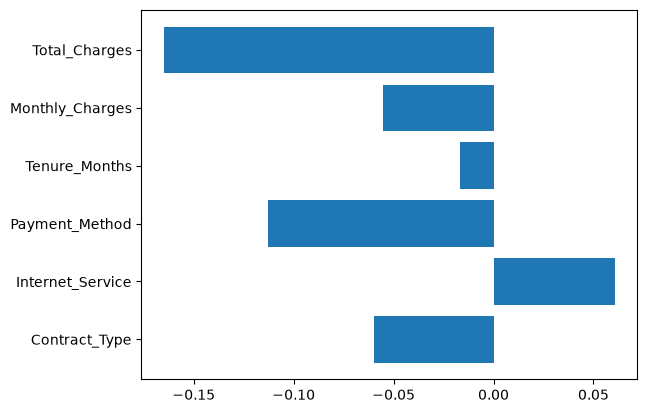

In [145]:
plt.barh(x.columns,model.coef_[0])

### CUSTOMERS ARE CHURNING DUE TO POOR INTERNET SERVICE.